# Brazilian E-Commerce Exploratory Data Analysis

## Project Overview
Analysis of the Brazilian E-Commerce Public Dataset by Olist.

### Objectives
- Explore sales and order patterns.
- Analyse customer behaviour.
- Investigate product performance.
- Evaluate delivery performance.
- Examine customer reviews.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [50]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
C:\Users\embra\PycharmProjects\PythonProject\olist-ecommerce-analysis\notebooks

Files and folders here:
['.ipynb_checkpoints', 'olist_exploratory_data_analysis.ipynb']


In [51]:
customers_df = pd.read_csv('../data/olist_customers_dataset.csv')
orders_df = pd.read_csv('../data/olist_orders_dataset.csv')
order_items_df = pd.read_csv('../data/olist_order_items_dataset.csv')
reviews_df = pd.read_csv('../data/olist_order_reviews_dataset.csv')
customers_df = customers_df.copy()
orders_df = orders_df.copy()
order_items_df = order_items_df.copy() 
reviews_df = reviews_df.copy()
print(customers_df.head())

                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  


In [52]:
print("Customers:", customers_df.shape)
print("Orders:", orders_df.shape)
print("Order Items:", order_items_df.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Order Items: (112650, 7)


In [53]:
print("CUSTOMERS DATASET")
customers_df.info()

print("\nORDERS DATASET")
orders_df.info()

print("\nORDER ITEMS DATASET")
order_items_df.info()

CUSTOMERS DATASET
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB

ORDERS DATASET
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   or

In [54]:
# checking missing values
null_customers = customers_df.isnull().sum()
null_orders = orders_df.isnull().sum()
null_order_items = order_items_df.isnull().sum() 
print('Null Customers')
print(null_customers)
print('\nNull Orders')
print(null_orders)
print('\nNull Order Items')
print(null_order_items)

Null Customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Null Orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Null Order Items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [55]:
percent_null_order = orders_df.isnull().mean() * 100
print(percent_null_order)

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64


In [56]:
order_value_counts = orders_df['order_status'].value_counts()
print(order_value_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [57]:
missing_delivery_by_status = (orders_df.groupby('order_status')
    ['order_delivered_customer_date'].apply(lambda x: x.isnull().sum()))
print(missing_delivery_by_status)

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64


In [58]:
# filtering orders_df
filtered_df = orders_df.loc[(orders_df['order_status'] == 'delivered') & (orders_df['order_delivered_customer_date'].isnull())]
print(filtered_df)

                               order_id                       customer_id  \
3002   2d1e2d5bf4dc7227b3bfebb81328c15f  ec05a6d8558c6455f0cbbd8a420ad34f   
20618  f5dd62b788049ad9fc0526e3ad11a097  5e89028e024b381dc84a13a3570decb4   
43834  2ebdfc4f15f23b91474edf87475f108e  29f0540231702fda0cfdee0a310f11aa   
79263  e69f75a717d64fc5ecdfae42b2e8e086  cfda40ca8dd0a5d486a9635b611b398a   
82868  0d3268bad9b086af767785e3f0fc0133  4f1d63d35fb7c8999853b2699f5c7649   
92643  2d858f451373b04fb5c984a1cc2defaf  e08caf668d499a6d643dafd7c5cc498a   
97647  ab7c89dc1bf4a1ead9d6ec1ec8968a84  dd1b84a7286eb4524d52af4256c0ba24   
98038  20edc82cf5400ce95e1afacc25798b31  28c37425f1127d887d7337f284080a0f   

      order_status order_purchase_timestamp    order_approved_at  \
3002     delivered      2017-11-28 17:44:07  2017-11-28 17:56:40   
20618    delivered      2018-06-20 06:58:43  2018-06-20 07:19:05   
43834    delivered      2018-07-01 17:05:11  2018-07-01 17:15:12   
79263    delivered      2018-07-01

In [59]:
#converting timestamp to datetime object
orders_df['order_purchase_timestamp'] = pd.to_datetime(orders_df['order_purchase_timestamp'])
orders_df['order_approved_at'] = pd.to_datetime(orders_df['order_approved_at'])
orders_df['order_delivered_carrier_date'] = pd.to_datetime(orders_df['order_delivered_carrier_date'])
orders_df['order_delivered_customer_date'] = pd.to_datetime(orders_df['order_delivered_customer_date'])
orders_df['order_estimated_delivery_date'] = pd.to_datetime(orders_df['order_estimated_delivery_date'])
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [60]:
orders_df['delivery_time_days'] = (orders_df['order_delivered_customer_date'] - 
                                   orders_df['order_purchase_timestamp']).dt.days 
print(orders_df['delivery_time_days'].describe())


count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time_days, dtype: float64


In [61]:
#delivery_delay
orders_df['delivery_delay'] = (orders_df['order_delivered_customer_date'] -
                               orders_df['order_estimated_delivery_date']).dt.days
print(orders_df['delivery_delay'].describe())

count    96476.000000
mean       -11.876881
std         10.183854
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
max        188.000000
Name: delivery_delay, dtype: float64


In [62]:
#delivery performance
conditions = [orders_df['delivery_delay'] < 0, orders_df['delivery_delay'] == 0, 
              orders_df['delivery_delay'] > 0]
choices = ['Early', 'On Time', 'Late']
orders_df['delivery_performance'] = np.select(conditions, choices, default='Unknown')
print('Value Counts')
print(orders_df['delivery_performance'].value_counts())
print('Percentage Count')
print(orders_df['delivery_performance'].value_counts(normalize=True) * 100)
#known delivery dates
known_delivery = orders_df[orders_df['delivery_performance'] != 'Unknown']
print('Known Delivery')
print(known_delivery['delivery_performance'].value_counts(normalize=True) * 100)

Value Counts
delivery_performance
Early      88649
Late        6535
Unknown     2965
On Time     1292
Name: count, dtype: int64
Percentage Count
delivery_performance
Early      89.147334
Late        6.571736
Unknown     2.981668
On Time     1.299263
Name: proportion, dtype: float64
Known Delivery
delivery_performance
Early      91.887101
Late        6.773705
On Time     1.339193
Name: proportion, dtype: float64


In [63]:
print(reviews_df.head())
print(reviews_df.info())

                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   review_score review_comment_title  \
0             4                  NaN   
1             5                  NaN   
2             5                  NaN   
3             5                  NaN   
4             5                  NaN   

                              review_comment_message review_creation_date  \
0                                                NaN  2018-01-18 00:00:00   
1                                                NaN  2018-03-10 00:00:00   
2                                                NaN  2018-02-17 00:00:00   
3           

In [64]:
print(reviews_df['order_id'].duplicated().sum())

551


In [65]:
duplicate_reviews = reviews_df[
    reviews_df['order_id'].duplicated(keep=False)
].sort_values('order_id')

print(duplicate_reviews.head(10))

                              review_id                          order_id  \
25612  89a02c45c340aeeb1354a24e7d4b2c1e  0035246a40f520710769010f752e7507   
22423  2a74b0559eb58fc1ff842ecc999594cb  0035246a40f520710769010f752e7507   
22779  ab30810c29da5da8045216f0f62652a2  013056cfe49763c6f66bda03396c5ee3   
68633  73413b847f63e02bc752b364f6d05ee9  013056cfe49763c6f66bda03396c5ee3   
854    830636803620cdf8b6ffaf1b2f6e92b2  0176a6846bcb3b0d3aa3116a9a768597   
83224  d8e8c42271c8fb67b9dad95d98c8ff80  0176a6846bcb3b0d3aa3116a9a768597   
17582  017f0e1ea6386de662cbeba299c59ad1  02355020fd0a40a0d56df9f6ff060413   
89888  0c8e7347f1cdd2aede37371543e3d163  02355020fd0a40a0d56df9f6ff060413   
55137  61fe4e7d1ae801bbe169eb67b86c6eda  029863af4b968de1e5d6a82782e662f5   
37911  04d945e95c788a3aa1ffbee42105637b  029863af4b968de1e5d6a82782e662f5   

       review_score review_comment_title  \
25612             5                  NaN   
22423             5                  NaN   
22779             5 

In [66]:
# Count reviews per order
reviews_per_order = reviews_df.groupby('order_id').size()

# Number of orders with multiple reviews
print('Orders with multiple reviews:',
      (reviews_per_order > 1).sum())

# Maximum number of reviews for one order
print('Maximum reviews per order:',
      reviews_per_order.max())

# Number of orders with different review scores
score_variation = reviews_df.groupby('order_id')['review_score'].nunique()

print('Orders with different review scores:',
      (score_variation > 1).sum())

Orders with multiple reviews: 547
Maximum reviews per order: 3
Orders with different review scores: 202


In [67]:
order_reviews = (
    reviews_df.groupby('order_id')['review_score']
    .mean()
    .reset_index()
)
print(order_reviews.head())
print(order_reviews.shape)

                           order_id  review_score
0  00010242fe8c5a6d1ba2dd792cb16214           5.0
1  00018f77f2f0320c557190d7a144bdd3           4.0
2  000229ec398224ef6ca0657da4fc703e           5.0
3  00024acbcdf0a6daa1e931b038114c75           4.0
4  00042b26cf59d7ce69dfabb4e55b4fd9           5.0
(98673, 2)


In [68]:
delivery_reviews = orders_df[
    ['order_id', 'delivery_performance']
]

print(delivery_reviews.head())
print(delivery_reviews.shape)

                           order_id delivery_performance
0  e481f51cbdc54678b7cc49136f2d6af7                Early
1  53cdb2fc8bc7dce0b6741e2150273451                Early
2  47770eb9100c2d0c44946d9cf07ec65d                Early
3  949d5b44dbf5de918fe9c16f97b45f8a                Early
4  ad21c59c0840e6cb83a9ceb5573f8159                Early
(99441, 2)


In [69]:
# merging delivery reviews and delivery performance
delivery_satisfaction = pd.merge(delivery_reviews, order_reviews, 
                                 on= 'order_id', how='left')
print(delivery_satisfaction.head())
print(delivery_satisfaction.shape)

                           order_id delivery_performance  review_score
0  e481f51cbdc54678b7cc49136f2d6af7                Early           4.0
1  53cdb2fc8bc7dce0b6741e2150273451                Early           4.0
2  47770eb9100c2d0c44946d9cf07ec65d                Early           5.0
3  949d5b44dbf5de918fe9c16f97b45f8a                Early           5.0
4  ad21c59c0840e6cb83a9ceb5573f8159                Early           5.0
(99441, 3)


In [70]:
satisfaction_by_delivery = (delivery_satisfaction.groupby('delivery_performance')['review_score']
                           .mean()
                           .sort_values(ascending=False))
print(satisfaction_by_delivery)   

delivery_performance
Early      4.294151
On Time    4.035547
Late       2.271937
Unknown    1.753254
Name: review_score, dtype: float64


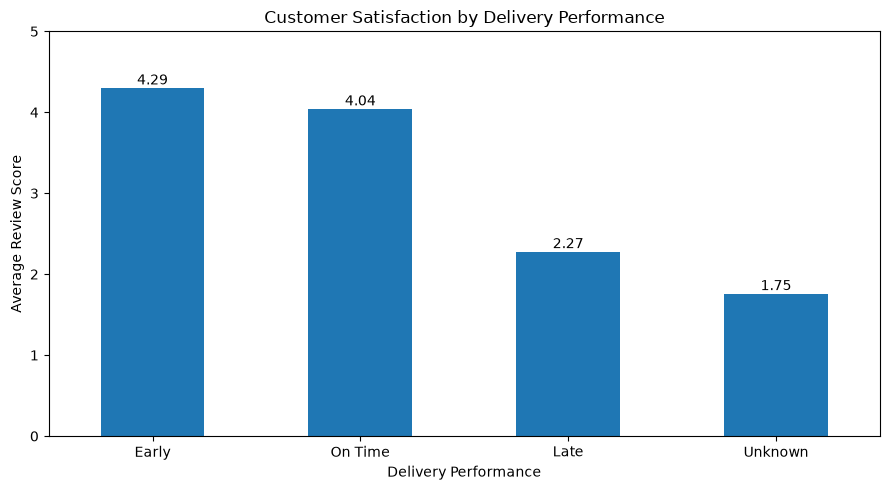

In [71]:
# visualizing satisfaction by delivery
satisfaction_by_delivery.plot(kind='bar', figsize=(9,5),
                             title = 'Customer Satisfaction by Delivery Performance',
                             xlabel ='Delivery Performance',
                             ylabel = 'Average Review Score')
plt.xticks(rotation=0)
plt.ylim(0, 5)
for i, value in enumerate(satisfaction_by_delivery):
    plt.text(i, value + 0.05, f'{value:.2f}', ha='center')
plt.tight_layout() 
plt.savefig(
    '../charts/customer_satisfaction_by_delivery.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [72]:
#Delivery Satisfaction Summary
satisfaction_summary = (
    delivery_satisfaction[
        delivery_satisfaction['delivery_performance'] != 'Unknown'
    ]
    .groupby('delivery_performance')['review_score']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

print(satisfaction_summary)

                      count  mean  median   std
delivery_performance                           
Early                 88168  4.29     5.0  1.15
Late                   6382  2.27     1.0  1.57
On Time                1280  4.04     5.0  1.25


In [73]:
# Exclude orders with unknown delivery performance
known_orders = delivery_satisfaction[
    delivery_satisfaction['delivery_performance'] != 'Unknown'
].copy()

# Identify poor customer ratings
known_orders['poor_review'] = (
    known_orders['review_score'] <= 2
)

# Calculate percentage of poor reviews
poor_review_rate = (
    known_orders.groupby('delivery_performance')['poor_review']
    .mean() * 100
)

print(poor_review_rate.round(2))

delivery_performance
Early       9.14
Late       60.89
On Time    12.15
Name: poor_review, dtype: float64


In [74]:
#comapring poor rating for early and late deliveries
late_rate = poor_review_rate['Late']
early_rate = poor_review_rate['Early']

relative_ratio = late_rate / early_rate

print('Late-to-early poor review rate ratio:',
      round(relative_ratio, 2))

Late-to-early poor review rate ratio: 6.66


### Delivery Performance and Customer Satisfaction

The analysis revealed a strong relationship between delivery performance and customer satisfaction.

Orders delivered late had a poor-review rate **6.66 times higher** than orders delivered early. Approximately 60.89% of late-delivery orders received an average review score of 2 or below, compared with just 9.14% of early-delivery orders.

The average customer review score was also considerably lower for late deliveries (2.27/5) than for early deliveries (4.29/5).

**Business Insight:**

Delivery reliability appears to be an important factor associated with customer satisfaction. Olist should investigate the causes of late deliveries and improve its logistics and delivery processes to reduce customer dissatisfaction.

**Recommendation:**

Monitor delivery delays, identify underperforming logistics routes and sellers, and improve estimated delivery times to create more reliable customer experiences.

In [75]:
#creating a contingency table
contingency_table = pd.crosstab(known_orders['delivery_performance'], 
                               known_orders['poor_review'])
print(contingency_table)


poor_review           False  True 
delivery_performance              
Early                 80545   8104
Late                   2556   3979
On Time                1135    157


In [76]:
print(contingency_table)
print(type(contingency_table))
print(contingency_table.shape)

poor_review           False  True 
delivery_performance              
Early                 80545   8104
Late                   2556   3979
On Time                1135    157
<class 'pandas.DataFrame'>
(3, 2)


In [77]:
print(known_orders.shape)
print(known_orders.columns.tolist())
print(known_orders['delivery_performance'].value_counts())

(96476, 4)
['order_id', 'delivery_performance', 'review_score', 'poor_review']
delivery_performance
Early      88649
Late        6535
On Time     1292
Name: count, dtype: int64


In [78]:
import sys

print(sys.executable)

C:\Users\embra\miniconda3-pbe\envs\retailfix\python.exe


In [79]:
%pip install scipy
from scipy.stats import chi2_contingency

print("SciPy installed successfully!")

Note: you may need to restart the kernel to use updated packages.
SciPy installed successfully!


In [80]:
import scipy

print(scipy.__version__)

1.18.1
